# Pengantar

Pada Kuis 1 ini Anda diminta untuk melakukan proses explorartory data analysis (EDA) dan pra pengolahan data pada dataset "Census Income". Dataset ini merupakan data tabular yang memiliki beberapa nilai yang hilang (missing value) dan nama variabel (fitur) yang perlu disesuaikan.

Untuk membantu Anda, notebook ini akan memberikan kode awal untuk proses download data, load data, dan inspeksi informasi terkait dengan metadata.

# Load Data and Inspect Metadata

In [1]:
# Install UCI REPO Library
!pip install -q ucimlrepo

In [2]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [3]:
# fetch data
adult_income = fetch_ucirepo(id=2)

In [4]:
# Data
X = adult_income.data.features
y = adult_income.data.targets

# Concate Features and Target
df = pd.concat([X, y], axis=1)

# Show Top 5
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
# Data Size
df.shape

(48842, 15)

In [6]:
# Inspect metadata
adult_income.metadata

{'uci_id': 2,
 'name': 'Adult',
 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult',
 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv',
 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ',
 'area': 'Social Science',
 'tasks': ['Classification'],
 'characteristics': ['Multivariate'],
 'num_instances': 48842,
 'num_features': 14,
 'feature_types': ['Categorical', 'Integer'],
 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'],
 'target_col': ['income'],
 'index_col': None,
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 1996,
 'last_updated': 'Tue Sep 24 2024',
 'dataset_doi': '10.24432/C5XW20',
 'creators': ['Barry Becker', 'Ronny Kohavi'],
 'intro_paper': None,
 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was ex

# Bagian 1 - Data Loading dan Data Imputation

## Soal 1 (5 poin)
1.   Lakukan inspeksi profile data
2.   **Variabel apa** yang memiliki **nilai yang hilang** (missing value) dan **berapa** jumlahnya?



In [7]:
# Jawab Soal 1
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan
# 1. Melakukan inspeksi data untuk mengetahui tipe data dari tiap variabelnya
df.info()

# 2. Cek variabel yang memiliki nilai yang hilang beserta jumlah yang hilang
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Dari ouput diatas kita mengetahui variabel beserta tipe datanya. Dan Variabel yang memiliki nilai hilang ada 3, yakni:
1. variabel workclass dengan data yang hilang sebanyak 963 data
2. variabel occupation dengan data yang hilang sebanyak 966
3. variabel native-country dengan data yang hilang sebanyak 274

## Soal 2 (5 poin)
1. Lakukan proses data imputation pada fitur yang memiliki data yang hilang
2. Cek kembali apakah masih terdapat data yang hilang

In [8]:
# Jawab Soal 2
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

fitur_hilang = ['workclass', 'occupation', 'native-country']

for fitur in fitur_hilang:

    modus_fitur_hilang = df[fitur].mode()[0]

    df[fitur] = df[fitur].fillna(modus_fitur_hilang)

df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

## Soal 3 (10 poin)
Inspeksi semua fitur kualitatif. Jika terdapat value yang **tidak sesuai**, **ganti dengan 'Others'** atau yang sesuai atau jika terdapat duplikasi karena **kesalahan penulisan**, lakukan penyesuaian.

In [9]:
# Jawab Soal 2
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

df.select_dtypes(include='object').columns

C:\Users\hf\AppData\Local\Temp\ipykernel_12768\1515973805.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='str')

In [10]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False).to_string())


=== workclass ===
workclass
Private             34869
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
?                    1836
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10

=== education ===
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83

=== marital-status ===
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37

=== occupation ===
occupation
Prof-specialty       7138
Craft-repair         6112
Exec-managerial  

C:\Users\hf\AppData\Local\Temp\ipykernel_12768\978845616.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [11]:
df['workclass'] = df['workclass'].replace('?', 'Others')
df['occupation'] = df['occupation'].replace('?', 'Others')
df['native-country'] = df['native-country'].replace('?', 'Others')
df['income'] = df['income'].str.replace('.', '', regex=False)

In [12]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False).to_string())


=== workclass ===
workclass
Private             34869
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Others               1836
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10

=== education ===
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83

=== marital-status ===
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37

=== occupation ===
occupation
Prof-specialty       7138
Craft-repair         6112
Exec-managerial  

C:\Users\hf\AppData\Local\Temp\ipykernel_12768\978845616.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


# Bagian 2 - Visual Inspection



## Soal 1 - Visualisasi Data (20 poin)
Lakukan inspeksi visual pada,
1. Pada kolom 'age' dengan menggunakan histrogram
2. Pada kolom 'education' education menggunakan barchart
3. Pada kolom 'income' terhadap 'hours_per_week' menggunakan boxplot (kelompokkan berdasarkan kelompok income)
4. Pada kolom 'age' terhadap 'capital-gain' dan 'capital-loss' dengan lineplot (1 lineplot 2 data)

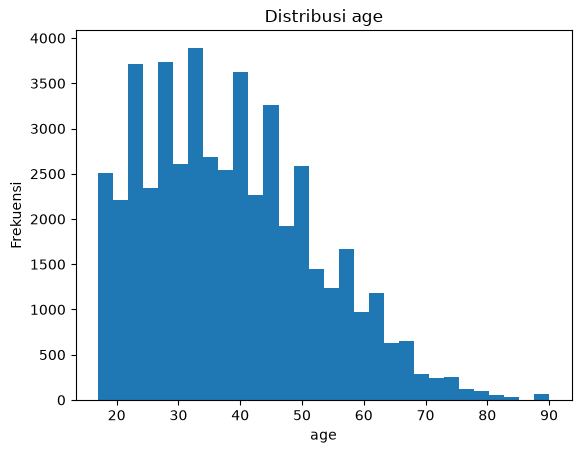

In [13]:
# Jawab 1.1 - Histrogram
num_cols = ['age']
for col in num_cols:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col); plt.ylabel('Frekuensi')
    plt.show()

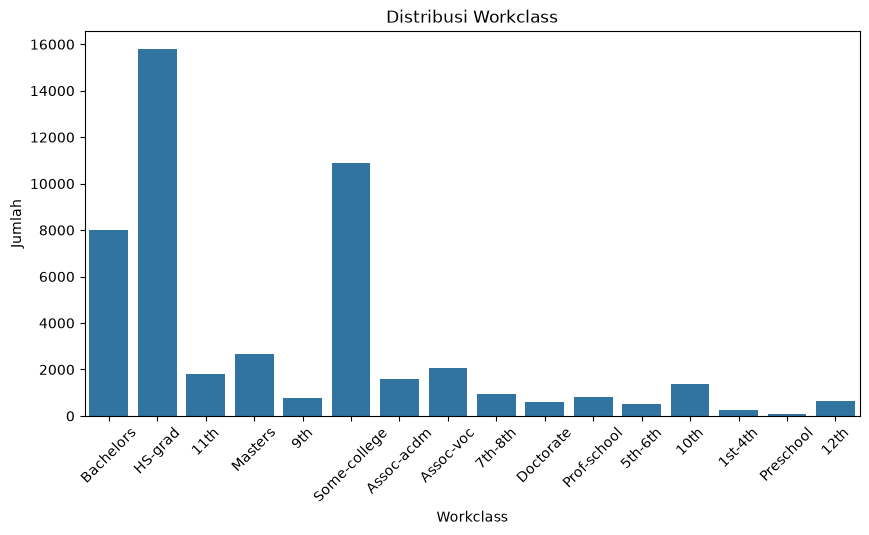

In [14]:
# Jawab 1.2 - Barchart
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='education')

plt.title('Distribusi Workclass')
plt.xlabel('Workclass')
plt.ylabel('Jumlah')
plt.xticks(rotation=45)
plt.show()

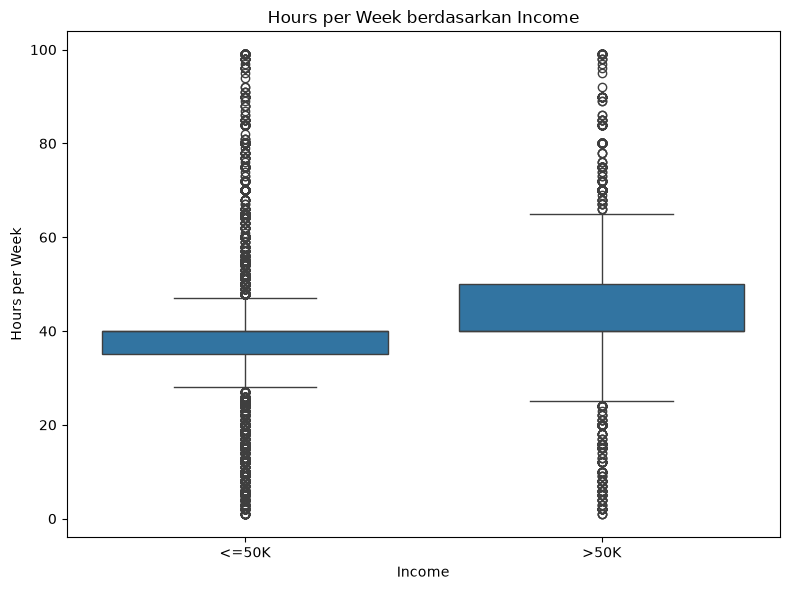

In [15]:
# Jawab 1.3 - Boxplot
fig, ax = plt.subplots(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='income',
    y='hours-per-week',
    ax=ax
)

ax.set_title('Hours per Week berdasarkan Income')
ax.set_xlabel('Income')
ax.set_ylabel('Hours per Week')

plt.tight_layout()
plt.show()

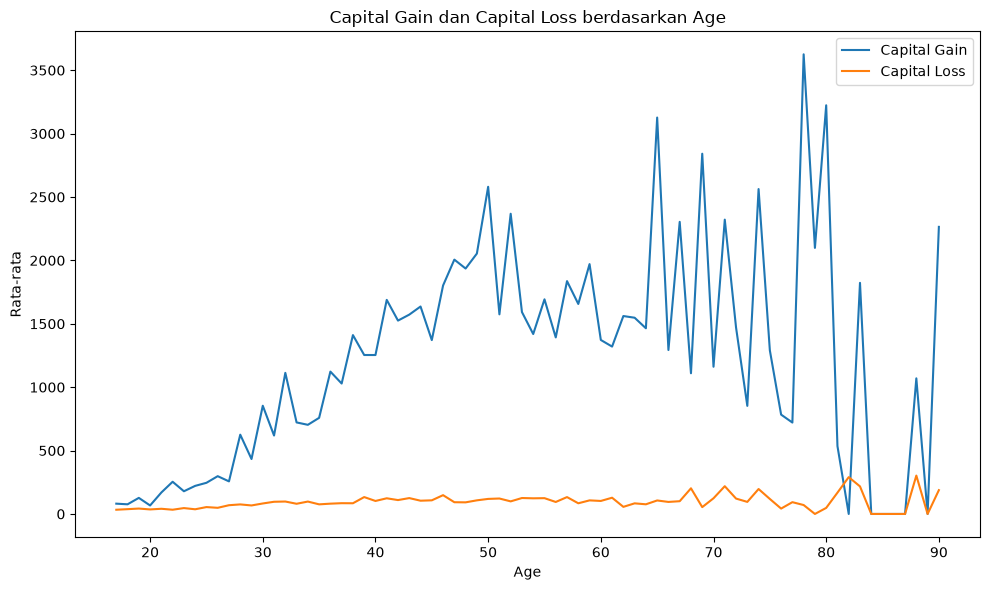

In [16]:
# Jawab 1.4 - Lineplot
fig, ax = plt.subplots(figsize=(10, 6))

df.groupby('age')[['capital-gain', 'capital-loss']].mean().plot(
    kind='line',
    ax=ax
)

ax.set_title('Capital Gain dan Capital Loss berdasarkan Age')
ax.set_xlabel('Age')
ax.set_ylabel('Rata-rata')
ax.legend(['Capital Gain', 'Capital Loss'])

plt.tight_layout()
plt.show()

## Soal 2 - Analisis Visual (15 poin)
1. Fenomena apa yang terjadi pada distribusi data 'age'?
2. Jika terdapat data yang hilang pada variabel 'age', strategi apa yang Anda terapkan? Mengapa?
3. Berapa jumlah outlier pada setiap kategori 'income' berkaitan dengan 'hour-per-week'? Kategori apa yang paling banyak memiliki outlier?

In [17]:
# Jawab dengan komentar python
# 1. Pada distribusi age cenderung miring ke kanan, karena sebagian besar data berada pada usia dewasa muda hingga parubaya, 
#     sedangkan frekuensi usia yang lebih tua semakin sedikit
# 2. untuk variabel age yang merupakan data numerik, strategi yang cocok adalah imputasi menggunakan median. 
#     karena distribusi age cenderung miring dan mungkin memiliki nilai ekstrem sehingga median lebih kuat erhadap outlier 
#     dibandingkan mean
# 3. 
for income in df['income'].unique():
    data = df[df['income'] == income]['hours-per-week']

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = data[(data < lower) | (data > upper)]

    print(f'{income}: {len(outlier)} outlier')
# outlier pada hours-per-week dihitung menggunakan metode IQR untuk masing-masing kategori income. 
# kategori dengan jumlah outlier terbanyak dapat diketahui dari hasil perhitungan tersebut.

<=50K: 11706 outlier
>50K: 781 outlier


# Bagian 3 - Encoding Variabel Kategorical

## Soal 1 (5 poin)
Lakukan encoding pada 'Sex' dan 'Income'. 'Income' merupakan variabel target

In [19]:
# Jawab Soal 1
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan
# Pilih variabel yang dianggap sebagai fitur
df_slice = df[['sex', 'income']]
df_slice.head()

,sex,income
0,Male,<=50K
1,Male,<=50K
2,Male,<=50K
3,Male,<=50K
4,Female,<=50K


In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_slice['sex'] = le.fit_transform(df_slice['sex'])
df_slice['income'] = le.fit_transform(df_slice['income'])
df_slice.head()

,sex,income
0,1,0
1,1,0
2,1,0
3,1,0
4,0,0


# Bagian 4 - Analisis Korelasi

## Soal 1 (10 poin)
1. Lakukan analisis korelasi pada variabel 'age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', dan 'income' (yang sudah di-encoding)
2. Berdasarkan hasil korelasi, informasi apa yang dapat Anda interpretasikan?

,age,education-num,hours-per-week,capital-gain,capital-loss,income
age,1.000000,0.030940,0.071558,0.077229,0.056944,0.230369
education-num,0.030940,1.000000,0.143689,0.125146,0.080972,0.332613
hours-per-week,0.071558,0.143689,1.000000,0.082157,0.054467,0.227687
capital-gain,0.077229,0.125146,0.082157,1.000000,-0.031441,0.223013
capital-loss,0.056944,0.080972,0.054467,-0.031441,1.000000,0.147554
income,0.230369,0.332613,0.227687,0.223013,0.147554,1.000000


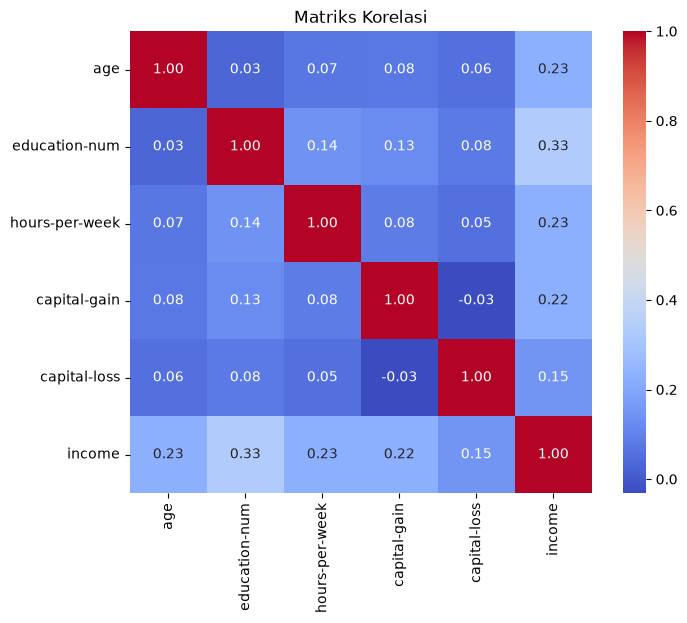

In [ ]:
# Jawab Soal 1
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

df['income'] =  df_slice['income']

kolom_korelasi = ['age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'income']

korelasi = df[kolom_korelasi].corr()

display(korelasi)

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Matriks Korelasi')
plt.show()

In [ ]:
# Hasil analisis jelaskan pada cell ini
# Education-num dengan income memiliki korelasi paling tinggi, yaitu 0,33. Artinya, semakin tinggi tingkat pendidikan, ada kecenderungan income juga meningkat, walaupun hubungannya masih tergolong lemah.
# Age dengan income memiliki korelasi 0,23, sehingga umur memiliki hubungan positif dengan income, tetapi tidak terlalu kuat.
# Hours-per-week dengan income juga sebesar 0,23, yang menunjukkan bahwa jumlah jam kerja per minggu memiliki hubungan positif dengan income.
# Capital-gain dengan income sebesar 0,22, sedangkan capital-loss dengan income sebesar 0,15. Keduanya masih menunjukkan hubungan positif, tetapi cukup lemah.
# Antar fitur seperti age, education-num, hours-per-week, capital-gain, dan capital-loss juga memiliki korelasi yang rendah, sebagian besar di bawah 0,15. Bahkan capital-gain dengan capital-loss memiliki korelasi negatif sangat kecil, yaitu -0,03, yang berarti hampir tidak ada hubungan linear.

# Bagian 5 - Pra Pengolahan Data Pada Dataset MNIST

Pada bagian ini, Anda diminta untuk melakukan proses EDA dan pra pengolahan data sederhana pada dataset MNIST. Dataset MNIST merupakan data citra tulisan tangan untuk digil 0 hingga 9. Sebelum melakukan proses pengolahan, Anda akan dibantu dengan proses loading data dan inspeksi data.

Hints:
1. Hanya gunakan data **Test**
2. Anda perlu melakukan pengolahan terhadap semua data test (total 10k data). Anda dapat menggunakan function untuk mempermudah pekerjaan.

In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Fetch data and inspect data shape
from tensorflow.keras.datasets import mnist
import numpy as np

# Load train & test split
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step
Train shape: (60000, 28, 28)
Test shape: (10000, 28, 28)


In [7]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.7 MB/s eta 0:00:06
   -- ------------------------------------- 0.5/9.3 MB 1.7 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/9.3 MB 1.0 MB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.3 MB 1.2 MB/s eta 0:00:08
   ----- ---------------------------------- 1.3/9.3 MB 1.2 MB/s eta 0:00:07
   ------ --------------------------------- 1.6/9.3 MB 1.1 MB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.3 MB 1.2 MB/s eta 0:00:06
   ---------- ----------------------------- 2.4/9.3 MB 1.3 MB/s eta 0:00:06
   ----------- ---------------------------- 2.6/9.3 MB 1.3 MB/s eta 0:00:06
   ------------- -------------------------- 3.1/

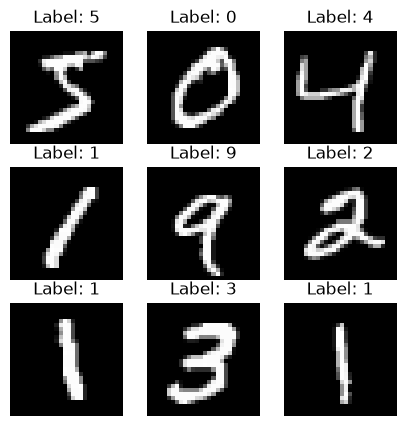

In [8]:
# Inspeksi Visual
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

## Soal 1 (10 poin)
1. Lakukan proses **upsampling** citra menjadi ukuran 32x32
2. Tampilakan 5 data hasil proses **upsampling**

Hint: Anda harus membuat array kosong untuk menampung hasil upsampling. Replace pada array X_test tidak dapat dilakukan karena data disimpan dalam bentuk ndarray yang memiliki ukuran fix (10000, (28,28))

In [10]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [11]:
# Jawab Soal 1
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Membuat array kosong untuk menampung hasil upsampling
X_test_resize = np.zeros((len(X_test), 32, 32), dtype=X_test.dtype)

# Upsampling semua data test
for i in range(len(X_test)):
    X_test_resize[i] = cv2.resize(
        X_test[i],
        (32, 32),
        interpolation=cv2.INTER_LINEAR
    )

print("Shape sebelum resize :", X_test.shape)
print("Shape setelah resize :", X_test_resize.shape)

Shape sebelum resize : (10000, 28, 28)
Shape setelah resize : (10000, 32, 32)


## Soal 2 (10 poin)
Lakukan normalisasi nilai citra tiap piksel menjadi rentang 0-1

In [12]:
# Jawab Soal 2
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

# Normalisasi nilai piksel menjadi 0-1
X_test_normalized = X_test_resize.astype(np.float32) / 255.0

print("Nilai minimum:", X_test_normalized.min())
print("Nilai maksimum:", X_test_normalized.max())
print("Shape:", X_test_normalized.shape)

Nilai minimum: 0.0
Nilai maksimum: 1.0
Shape: (10000, 32, 32)


## Soal 3 (10 poin)
Ubah metriks citra menjadi array 1 dimensi. Lakukan pada semua data test yang sudah di resize dan normalisasi.

Hint: Anda harus membuat holder array kosong untuk menampung hasilnya.

In [13]:
# Jawab Soal 3
# Kerjakan pada cell ini
# Anda diperbolehkan menambah cell jika diperlukan

# Membuat holder array kosong
X_test_flatten = np.zeros(
    (len(X_test_normalized), 32 * 32),
    dtype=np.float32
)

# Flatten semua data test
for i in range(len(X_test_normalized)):
    X_test_flatten[i] = X_test_normalized[i].flatten()

print("Shape hasil flatten:", X_test_flatten.shape)

Shape hasil flatten: (10000, 1024)
